# 03 - Feature engineering

The four features of Study 1 are counted here, from `text_clean` with the full
spaCy `en_core_web_lg` pipeline. Tagger and parser are needed for F2 and F4.

- **Question:** How are the four linguistic quantities of Study 1 measured, and
  does the implementation in `src/` give the same values as the notebook?
- **Expectation:** none directional; the notebook measures.
- **Status:** third step of the series. Dictionary A is the main analysis,
  fixed on 2026-10-10 before any result with A was seen.
- **Unit and test:** biography; counts and rates, a runtime test on 5,000
  biographies, and a control that the inline logic and the logic of `src/`
  agree token for token.
- **Inputs:** `outputs/df_preprocessed.parquet` (biographies with `text_clean`)
  and `data/lexicons/official/a_AgencyCommunion.dic`.
- **Outputs:** `outputs/df_features.parquet` - the columns of the input plus
  the four features, `attribution_passive_rate_anyvoice` (the F4 robustness
  variant) and the raw hit counts `agency_count` and `communion_count` behind
  F1, which notebook 04 needs separately because they cannot be reconstructed
  from the ratio; and the figure `outputs/feature_correlation_matrix.png`.
- **Run:** from a fresh kernel, top to bottom, from the project root. The
  spaCy model occupies roughly 600 MB; the full pass runs over all
  biographies.
- **Decisions:** the main analysis uses dictionary A (194 agency and 186
  communion entries); the union A u B is the robustness variant and is
  computed in `04b_study1_robustness_lexicon_AB.ipynb`, not here. The F4 word
  list is built by the researcher and does not come from that source
  (section 6).

| Feature | Description | Method |
|---|---|---|
| `agentic_communal_ratio` | (agency - communion) / (agency + communion + 1) | Big Two dictionary, LIWC wildcard matching |
| `passive_ratio` | passive constructions / verb tokens | spaCy `auxpass` dependency |
| `achievement_verb_rate` | achievement hits / `word_count` x 100 | fixed subset of the agency terms |
| `attribution_passive_rate` | externally conferred recognition in the passive / `word_count` x 100 | researcher-built recognition lexicon (Weiner 1985) + `auxpass`, see section 6 |

**Dictionary:** Pietraszkiewicz, Formanowicz, Gustafsson Senden, Boyd, Sikstrom
& Sczesny (2019), *Big Two Dictionaries*, obtained from https://osf.io/p7fzb/
(retrieved 2026-06-19); dictionary A is
`data/lexicons/official/a_AgencyCommunion.dic`, the union A u B is
`data/lexicons/agency_communion.dic`.


## Contents

1. Data loading and spaCy pipeline
2. Dictionary construction
3. F1 - `agentic_communal_ratio`
4. F2 - `passive_ratio`
5. F3 - `achievement_verb_rate`
6. F4 - `attribution_passive_rate`
7. Runtime test on 5,000 biographies
8. Full pass over all biographies
9. Feature correlations
10. Export to `src/`
11. Save `outputs/df_features.parquet`

Numbers live in the cell outputs, not in the markdown. Each section states what
is being checked; the values themselves are printed by the code.

## 1. Data Loading & spaCy Pipeline

The full `en_core_web_lg` pipeline is loaded with only `ner` disabled - the `tagger` (POS tags) and `parser` (dependency labels including `auxpass`) are both required for F2-F4. Disabling `ner` saves ~15% processing time with no loss of information for these features.

In [1]:
import os
import sys

# -- Avoid the OpenMP conflict (must precede the numpy import) ----------------
# NumPy uses Intel MKL in this environment and loads libiomp5md.dll; torch ships
# a second copy of the same DLL. Once both land in one process it aborts with
# "OMP: Error #15", which inside a Jupyter kernel means a kernel crash. It first
# showed up in the F2 cell, the first one to put real load on the parser.
# SEQUENTIAL keeps MKL single-threaded and avoids loading Intel's OpenMP at all.
# Verified to leave every count unchanged (validation notebook, point 2).
# Do not use KMP_DUPLICATE_LIB_OK: Intel documents that it can produce wrong
# results silently.
# Takes effect only while numpy has not yet been imported in this kernel, so run
# from a fresh kernel.
os.environ.setdefault("MKL_THREADING_LAYER", "SEQUENTIAL")

import pandas as pd
import numpy as np
import spacy
import re
from pathlib import Path
from tqdm.auto import tqdm

# -- Working directory -> project root -----------------------------------------

# The notebook may be opened from notebooks/, from the project root or from a
# copy in notebooks/archive/. The root is the nearest folder upwards that holds
# both outputs/ and src/, so every path below can be written relative to it.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'outputs').is_dir() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('project root not found: no folder at or above the '
                       'working directory holds both outputs/ and src/')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print(f"working directory: {ROOT.name}")
print(f"MKL_THREADING_LAYER = {os.environ.get('MKL_THREADING_LAYER')}")

# -- Data ----------------------------------------------------------------------
df = pd.read_parquet('outputs/df_preprocessed.parquet')
print(f"Loaded: {df.shape[0]:,} bios × {df.shape[1]} columns")
print(f"Columns: {list(df.columns)}")
print()

# -- spaCy pipeline ------------------------------------------------------------
# tagger  -> token.pos_ (VERB needed for passive_ratio denominator)
# parser  -> token.dep_ (auxpass needed for passive detection)
# ner     -> not used; disabled for speed
nlp = spacy.load('en_core_web_lg', disable=['ner'])
print(f"Pipeline components: {nlp.pipe_names}")

# Quick sanity check
sample = df['text_clean'].iloc[0]
doc = nlp(sample[:200])
print(f"\nSanity check — first bio excerpt (200 chars):")
print(f"  Text: {sample[:200]}")
print(f"  VERB tokens (text, pos, dep): {[(t.text, t.pos_, t.dep_) for t in doc if t.pos_ == 'VERB'][:5]}")

working directory: Thesis_Model
MKL_THREADING_LAYER = SEQUENTIAL
Loaded: 393,977 bios × 7 columns
Columns: ['hard_text', 'text_clean', 'profession', 'occupation', 'gender', 'gender_label', 'word_count']

Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']

Sanity check — first bio excerpt (200 chars):
  Text: is also the project lead of and major contributor to the open source assembler/simulator "EASy68K." earned a master’s degree in computer science from the University of Michigan-Dearborn, where is also
  VERB tokens (text, pos, dep): [('earned', 'VERB', 'conj')]


## 2. Dictionary construction

**Source:** Pietraszkiewicz, Formanowicz, Gustafsson Senden, Boyd, Sikstrom &
Sczesny (2019), *Big Two Dictionaries*, LIWC format. This notebook uses
dictionary A, `data/lexicons/official/a_AgencyCommunion.dic`, obtained from
https://osf.io/p7fzb/ (retrieved 2026-06-19).

**Number of entries:** the file contains 194 agency and 186 communion entries.
The paper reports 192 and 184 because the file spells out `think*` and `team*`
as three words each. Entries are counted as (term, category) pairs; a term that
appears in both categories counts twice. Three communion entries consist of
several words and are handled separately, which is why the output below reports
183 single-word communion entries.

**Matching rules (fixed, for comparability with De-Arteaga 2019):**
- Exact entries: equality with the lowercased token form
  (`token.lower_ in exact_set`)
- Wildcard entries (ending in `*`): prefix match on the token form
- No lemmatisation - matching surface forms preserves the LIWC validation
- The three multi-word entries (`common good`, `common ground*`,
  `middle ground`) are searched in the text, not over tokens

**Achievement dictionary:** a fixed subset of the agency terms aimed at discrete
achievement events. Four borderline terms (`effective*`, `productive*`,
`acquir*`, `completion`) remain excluded because they describe general
competence rather than a specific event. Under dictionary A the list has 23
entries. `excellent*` and `outstanding*` are not among them: they appear only in
dictionary B and therefore only in the robustness variant.

**Relation to `src/lexicon.py`:** this cell derives the logic;
`src/lexicon.py` is authoritative for all later notebooks. Section 10 uses a
smoke test to confirm that both paths produce the same values and that the file
path used here is the one `load_lexicons(version="A")` reads.

In [2]:
# -- Parse Pietraszkiewicz et al. (2019) Big Two dictionary -------------------

# Dictionary A is the main analysis (decision of 2026-10-10). This is the same
# path load_lexicons(version="A") uses; section 10 verifies that.
DIC_PATH = Path('data/lexicons/official/a_AgencyCommunion.dic')

def _parse_dic(path):
    """
    Parse LIWC-format .dic file.
    Returns: agency_exact, agency_wild (sorted stems),
             communion_exact, communion_wild (sorted stems),
             multi_word (list of (term, category, is_wildcard) for entries with spaces)
    """
    agency_exact, communion_exact = set(), set()
    agency_wild, communion_wild = [], []
    multi_word = []

    in_data = False
    pct_seen = 0
    for line in path.read_text(encoding='utf-8').splitlines():
        line = line.strip()
        if line == '%':
            pct_seen += 1
            if pct_seen == 2:
                in_data = True
            continue
        if not in_data or not line or '\t' not in line:
            continue
        term, cat = line.rsplit('\t', 1)
        term = term.lower().strip()
        cat = cat.strip()

        if ' ' in term:                         # multi-word → text-level matching
            is_wild = term.endswith('*')
            multi_word.append((term.rstrip('*'), cat, is_wild))
            continue

        is_wild = term.endswith('*')
        if cat == '1':
            agency_wild.append(term[:-1]) if is_wild else agency_exact.add(term)
        elif cat == '2':
            communion_wild.append(term[:-1]) if is_wild else communion_exact.add(term)

    return (agency_exact, sorted(agency_wild),
            communion_exact, sorted(communion_wild),
            multi_word)

(AGENCY_EXACT, AGENCY_WILD,
 COMMUNION_EXACT, COMMUNION_WILD,
 MULTI_WORD) = _parse_dic(DIC_PATH)

# -- Token-level matcher using LIWC wildcard semantics -------------------------
def _make_matcher(exact_set, wild_sorted):
    """
    Returns match(tok_lower) → bool.

    Wildcard lookup uses a single compiled alternation regex anchored at the
    start of the token. NOTE: an earlier version used binary search on sorted
    stems for O(log n) lookup -- that is INCORRECT when one stem is itself a
    prefix of another (e.g. 'affect' / 'affection', 'open' / 'open-mind'): the
    nearest sorted predecessor of a query like 'affects' is 'affection' (not
    'affect'), and 'affects'.startswith('affection') is False, silently dropping
    a real match. Fixed here with a compiled regex (correct, and fast enough at
    this scale via the C-level regex engine).
    """
    if wild_sorted:
        pattern = re.compile('^(?:' + '|'.join(re.escape(w) for w in wild_sorted) + ')')
    else:
        pattern = None

    def match(tok_lower):
        if tok_lower in exact_set:
            return True
        return pattern is not None and pattern.match(tok_lower) is not None
    return match

match_agency    = _make_matcher(AGENCY_EXACT, AGENCY_WILD)
match_communion = _make_matcher(COMMUNION_EXACT, COMMUNION_WILD)

# -- Multi-word communion matcher (text-level substring) -----------------------
_MULTI_C = [(t, w) for t, c, w in MULTI_WORD if c == '2']

def _count_multiword_communion(text_lower):
    """Count multi-word communion matches in lowercased text string."""
    count = 0
    for term, is_wild in _MULTI_C:
        pat = r'\b' + re.escape(term) + (r'\w*' if is_wild else r'') + r'\b'
        count += len(re.findall(pat, text_lower))
    return count

# -- Achievement lexicon (frozen Agency-A subset) ------------------------------

# Focuses on discrete accomplishment events, not general competence descriptors.
# Excluded borderline: effective*, productive*, acquir*, completion
# won't excluded: contraction artefact in dic (spaCy splits contractions anyway)
_ACH_EXACT = {
    'overcome', 'overcomes', 'mastered', 'mastering', 'mastery',
    'win', 'wins', 'won', 'earn', 'earned', 'earning', 'earns',
}
# Version A: 23 entries. 'excellent' and 'outstanding' appear only in
# dictionary B and therefore not in the main analysis.
_ACH_WILD = sorted([
    'accomplish', 'achiev', 'attain', 'succeed', 'success', 'triumph',
    'prevail', 'masterful', 'victor', 'winner', 'winning',
])

match_achievement = _make_matcher(_ACH_EXACT, _ACH_WILD)

# -- Term counts ---------------------------------------------------------------
print(f"=== Dictionary A: {DIC_PATH} ===")
print("=== Lexicon term counts ===")
print(f"Agency    (total {len(AGENCY_EXACT) + len(AGENCY_WILD):3d}):  "
      f"{len(AGENCY_EXACT)} exact + {len(AGENCY_WILD)} wildcard stems")
print(f"Communion (total {len(COMMUNION_EXACT) + len(COMMUNION_WILD):3d}):  "
      f"{len(COMMUNION_EXACT)} exact + {len(COMMUNION_WILD)} wildcard stems")
print(f"Multi-word (text-level, communion only): {len(_MULTI_C)} entries "
      f"→ {[t for t, _ in _MULTI_C]}")
print(f"\nAchievement subset (total {len(_ACH_EXACT) + len(_ACH_WILD)}):  "
      f"{len(_ACH_EXACT)} exact + {len(_ACH_WILD)} wildcard stems")
print(f"  Borderline EXCLUDED: effective*, productive*, acquir*, completion")
print()

# -- Spot-check ----------------------------------------------------------------
test_tokens = [
    'accomplished', 'leadership', 'collaborative', 'caring',
    'succeeded', 'won', "won't", 'achieved', 'community',
    'assertive', 'compassionate', 'outstanding', 'mastery',
    'affects', 'affection', 'openness', 'opened',
]
print("=== Spot-check: token matching ===")
for t in test_tokens:
    tags = []
    if match_agency(t):      tags.append('AGENCY')
    if match_communion(t):   tags.append('COMMUNION')
    if match_achievement(t): tags.append('ACHIEVEMENT')
    print(f"  {t:<22s} → {tags if tags else '—'}")

=== Dictionary A: data\lexicons\official\a_AgencyCommunion.dic ===
=== Lexicon term counts ===
Agency    (total 194):  86 exact + 108 wildcard stems
Communion (total 183):  62 exact + 121 wildcard stems
Multi-word (text-level, communion only): 3 entries → ['common good', 'common ground', 'middle ground']

Achievement subset (total 23):  12 exact + 11 wildcard stems
  Borderline EXCLUDED: effective*, productive*, acquir*, completion

=== Spot-check: token matching ===
  accomplished           → ['AGENCY', 'ACHIEVEMENT']
  leadership             → —
  collaborative          → ['COMMUNION']
  caring                 → ['COMMUNION']
  succeeded              → ['AGENCY', 'ACHIEVEMENT']
  won                    → ['AGENCY', 'ACHIEVEMENT']
  won't                  → ['AGENCY']
  achieved               → ['AGENCY', 'ACHIEVEMENT']
  community              → ['COMMUNION']
  assertive              → ['AGENCY']
  compassionate          → ['COMMUNION']
  outstanding            → —
  mastery         

**What is checked here:** that the file parses, how many agency, communion and
achievement entries it yields, and that matching fires correctly. The
single-token spot check shows the assignment to AGENCY, COMMUNION and
ACHIEVEMENT; the counts are in the cell output.

On the spot check: `won't` is an exact entry of the published dictionary (read as
determination). It has no practical consequence, because spaCy splits `"won't"`
into `["wo", "n't"]`, so the entry never fires on real biography tokens.
`excellent` and `outstanding` no longer match under dictionary A, as they are
B-only entries.

### Bug fix - the wildcard matcher undercounted communion

An earlier version of `_make_matcher` looked up wildcard stems by binary search
(`bisect`). That is wrong as soon as one stem is a prefix of another. For a token
like `"affects"` the nearest sorted predecessor is `"affection"`, not
`"affect"`, and `"affects".startswith("affection")` is false - the real match
was silently dropped. This produced systematic false negatives (never false
positives).

**Which version was affected.** The nested stems that triggered the bug -
`affect*` / `affection*` and `open*` / `open-mind*` - are **B-only entries**, so
the undercount applied to the union A u B, which was the main analysis until
2026-10-10. Dictionary A contains neither `affect*` nor `open*` and was never
affected by this particular pair. The fix is nevertheless version-independent
and is the one in force for both A and A u B: binary search was replaced by a
single compiled alternation regex (`^(?:stem1|stem2|...)`), which is correct for
any stem list and fast enough at this scale. Should a future dictionary contain
nested stems, the matcher handles them correctly.

Why this mattered: communion is the female-coded pole of the Big Two framework,
so an undercount shifts `agentic_communal_ratio` upward and could mask the very
gender difference this thesis measures. The spot check above includes `affects`,
`affection`, `openness` and `opened` to document the fix; under dictionary A
these tokens are expected not to match.

## 3. Feature 1 - `agentic_communal_ratio`

**Formula:** `(agency_hits - communion_hits) / (agency_hits + communion_hits + 1)`

- Bounded between -1 (purely communal) and +1 (purely agentic)
- The +1 in the denominator prevents division by zero for bios with zero lexicon hits
- `agency_hits`: count of tokens whose lowercased surface form matches any Agency-A entry
- `communion_hits`: token-level communion matches + text-level multi-word matches (`common good`, `common ground*`, `middle ground`)

The spot-check below shows matched terms for 20 bios, and coverage statistics on a 1,000-bio sample report the share of bios that have at least one agency/communion hit - low coverage would indicate a 3rd-person adaptation issue (bios written as "Dr. Smith leads..." instead of "I lead...").

In [3]:
# -- Feature 1: agentic_communal_ratio ----------------------------------------
def f1_agentic_communal_ratio(doc, text: str):
    """
    Compute agency hits, communion hits, and their ratio for one bio.
    doc  : spaCy Doc (pre-computed — reused across all feature functions)
    text : original text string (needed for multi-word communion substring search)

    Returns (agency_hits, communion_hits, agentic_communal_ratio)
    ratio = (A - C) / (A + C + 1)  — bounded (-1, +1)
    """
    agency_hits    = sum(1 for t in doc if match_agency(t.lower_))
    communion_hits = (sum(1 for t in doc if match_communion(t.lower_))
                      + _count_multiword_communion(text.lower()))
    ratio = (agency_hits - communion_hits) / (agency_hits + communion_hits + 1)
    return agency_hits, communion_hits, ratio

# -- Spot-check: 20 bios with matched terms -----------------------------------

# We use the same first-20 indices across all feature spot-checks for comparability.
SPOT_IDX = list(range(20))
sample_df = df.iloc[SPOT_IDX].copy()

print("=== F1 Spot-check — 20 bios ===\n")
for i, (_, row) in enumerate(sample_df.iterrows()):
    doc = nlp(row['text_clean'])
    a, c, ratio = f1_agentic_communal_ratio(doc, row['text_clean'])
    a_terms = [t.lower_ for t in doc if match_agency(t.lower_)]
    c_terms = [t.lower_ for t in doc if match_communion(t.lower_)]
    print(f"[{i:2d}] {row['occupation']:<22s} ({row['gender_label']})  "
          f"A={a:2d}  C={c:2d}  ratio={ratio:+.3f}")
    if a_terms: print(f"      AGENCY:    {a_terms}")
    if c_terms: print(f"      COMMUNION: {c_terms}")

# -- Coverage on 1,000-bio sample (using nlp.pipe for efficiency) --------------
print("\n=== F1 Coverage — 1,000-bio sample ===")
sample1k  = df.sample(1000, random_state=42)
texts1k   = sample1k['text_clean'].tolist()

a_counts, c_counts = [], []
for doc, text in zip(nlp.pipe(texts1k, batch_size=64), texts1k):
    a, c, _ = f1_agentic_communal_ratio(doc, text)
    a_counts.append(a)
    c_counts.append(c)

a_arr, c_arr = np.array(a_counts), np.array(c_counts)
print(f"  Bios with ≥1 agency hit:     {(a_arr > 0).mean()*100:.1f}%")
print(f"  Bios with ≥1 communion hit:  {(c_arr > 0).mean()*100:.1f}%")
print(f"  Bios with ≥1 of both:        {((a_arr > 0) & (c_arr > 0)).mean()*100:.1f}%")
print(f"  Mean agency hits (per bio):  {a_arr.mean():.2f}")
print(f"  Mean communion hits:         {c_arr.mean():.2f}")

=== F1 Spot-check — 20 bios ===

[ 0] professor              (Male)  A= 1  C= 1  ratio=+0.000
      AGENCY:    ['earned']
      COMMUNION: ['contributor']
[ 1] nurse                  (Female)  A= 2  C= 1  ratio=+0.250
      AGENCY:    ['able', 'independent']
      COMMUNION: ['care']
[ 2] attorney               (Female)  A= 1  C= 3  ratio=-0.400
      AGENCY:    ['earned']
      COMMUNION: ['law', 'law', 'law']
[ 3] journalist             (Male)  A= 0  C= 1  ratio=-0.500
      COMMUNION: ['contributes']
[ 4] professor              (Male)  A= 0  C= 1  ratio=-0.500
      COMMUNION: ['member']
[ 5] attorney               (Male)  A= 1  C= 3  ratio=-0.400
      AGENCY:    ['practiced']
      COMMUNION: ['law', 'member', 'member']
[ 6] professor              (Male)  A= 2  C= 4  ratio=-0.286
      AGENCY:    ['earned', 'practicing']
      COMMUNION: ['communities', 'fellow', 'learning', 'community']
[ 7] poet                   (Female)  A= 0  C= 1  ratio=-0.500
      COMMUNION: ['educator']
[

**What is checked here:** F1 coverage on a 1,000-biography sample (the share of
biographies with at least one agency hit, at least one communion hit, and at
least one of each, plus the mean number of hits per biography). The values are
in the cell output.

Coverage is lower than one might wish for short third-person biographies. The
dictionary was validated on six corpora - blogs, books, the New York Times,
spoken language, Twitter, and expressive writing - none of which is
third-person professional biography, so a lower hit rate on this material is
expected rather than surprising.

Coverage under dictionary A is markedly lower than the state before
2026-10-10, above all for agency. That follows from the entry lists: frequent
stems such as `lead*`, `creat*`, `experience*`, `professional*` and `strong*`
appear only in dictionary B and no longer count in the main analysis. The drop
for communion is smaller, because fewer frequent stems fall to B (among them
`care*`, `open*`, `understand*`, `warm*`).

**False positives in the spot check.** One pattern persists under dictionary A:
`law` is an exact communion entry, and in biographies of attorneys it is a
domain term. Occupation fixed effects in Study 1 absorb part of this. Two
further patterns documented before 2026-10-10 no longer occur under dictionary
A, because the entries concerned are B-only: `inform*` (matched `information`
and `informal` as agency) and `open*` (matched "open source" as communion).
These limits and their disappearance are reported in the methods section.

## 4. Feature 2 - `passive_ratio`

**Formula:** `passive_ratio = count(dep_ == "auxpass") / max(count(pos_ == "VERB"), 1)`

In the spaCy dependency tree, passive voice is marked by an auxiliary verb ("was", "is", "been") receiving the `auxpass` dependency label, with the past participle as its head. For example:
- `"was awarded the prize"` -> `"was"` gets `dep_="auxpass"`, head = `"awarded"` - passive
- `"she awarded the prize"` -> `"awarded"` gets `dep_="ROOT"` - no auxpass token - active

Counting `auxpass` tokens is therefore equivalent to counting passive clauses. The denominator (total VERB tokens) normalises for bio length and verb density, making the ratio comparable across bios of different lengths.

**Per-100-words fallback** is also reported as a robustness check - if the two denominators diverge strongly by gender, that would indicate the choice of denominator is non-trivial and should be flagged in the thesis.

In [4]:
# -- Feature 2: passive_ratio --------------------------------------------------
def f2_passive_ratio(doc, word_count: int):
    """
    Fraction of verb tokens that are passive auxiliaries.

    auxpass_count : number of tokens with dep_="auxpass" (one per passive clause)
    verb_count    : total VERB tokens (pos_="VERB") — normalises for verb density
    fallback      : passive per 100 words — robustness check vs VERB denominator

    Returns (auxpass_count, verb_count, passive_ratio, passive_per_100w)
    """
    auxpass_count = sum(1 for t in doc if t.dep_ == 'auxpass')
    verb_count    = sum(1 for t in doc if t.pos_ == 'VERB')
    ratio         = auxpass_count / max(verb_count, 1)
    per_100w      = auxpass_count / max(word_count, 1) * 100
    return auxpass_count, verb_count, ratio, per_100w

# -- Spot-check: same 20 bios, show passive constructions ---------------------
print("=== F2 Spot-check — 20 bios ===\n")
for i, (_, row) in enumerate(sample_df.iterrows()):
    doc = nlp(row['text_clean'])
    ap, vc, ratio, p100 = f2_passive_ratio(doc, row['word_count'])

    # Show the passive constructions: auxpass token + its head (the main verb)
    passives = [(t.text, t.head.text) for t in doc if t.dep_ == 'auxpass']

    print(f"[{i:2d}] {row['occupation']:<22s} ({row['gender_label']})  "
          f"auxpass={ap}  verbs={vc}  ratio={ratio:.3f}  per100w={p100:.2f}")
    if passives:
        print(f"      Passive constructions (aux → head verb): {passives}")

# -- Summary on 1,000-bio sample -----------------------------------------------
print("\n=== F2 Summary — 1,000-bio sample ===")
ratios, per100s = [], []
for doc, (_, row) in zip(nlp.pipe(texts1k, batch_size=64), sample1k.iterrows()):
    _, _, r, p = f2_passive_ratio(doc, row['word_count'])
    ratios.append(r)
    per100s.append(p)

r_arr = np.array(ratios)
p_arr = np.array(per100s)
print(f"  passive_ratio    — mean: {r_arr.mean():.4f}  median: {np.median(r_arr):.4f}  "
      f"max: {r_arr.max():.3f}")
print(f"  passive_per_100w — mean: {p_arr.mean():.4f}  median: {np.median(p_arr):.4f}  "
      f"max: {p_arr.max():.3f}")
print(f"  Bios with ≥1 passive clause: {(r_arr > 0).mean()*100:.1f}%")
print(f"\n  Correlation between two denominators: r={np.corrcoef(r_arr, p_arr)[0,1]:.4f}")
print(f"  → High correlation = denominator choice does not materially affect ranking")

=== F2 Spot-check — 20 bios ===

[ 0] professor              (Male)  auxpass=0  verbs=1  ratio=0.000  per100w=0.00
[ 1] nurse                  (Female)  auxpass=0  verbs=4  ratio=0.000  per100w=0.00
[ 2] attorney               (Female)  auxpass=1  verbs=4  ratio=0.250  per100w=1.52
      Passive constructions (aux → head verb): [('was', 'awarded')]
[ 3] journalist             (Male)  auxpass=1  verbs=2  ratio=0.500  per100w=3.23
      Passive constructions (aux → head verb): [('be', 'reached')]
[ 4] professor              (Male)  auxpass=0  verbs=4  ratio=0.000  per100w=0.00
[ 5] attorney               (Male)  auxpass=0  verbs=3  ratio=0.000  per100w=0.00
[ 6] professor              (Male)  auxpass=0  verbs=7  ratio=0.000  per100w=0.00
[ 7] poet                   (Female)  auxpass=0  verbs=5  ratio=0.000  per100w=0.00
[ 8] surgeon                (Male)  auxpass=1  verbs=3  ratio=0.333  per100w=1.59
      Passive constructions (aux → head verb): [('is', 'affiliated')]
[ 9] journalist   

**What is checked here:** that the `auxpass` dependency identifies genuine
passive constructions, which formulaic patterns it also picks up, how
zero-inflated the distribution is, and whether the choice of denominator
matters. The values are in the cell output.

The spot check confirms genuine attribution passives (`"was awarded"`,
`"was recognized"`, `"been featured"`). It also surfaces two formulaic noise
patterns - `"can be reached at"` and `"has been listed in"` - which are
standard biography boilerplate unrelated to self-presentation style. They
inflate passive counts for biographies that carry contact details or directory
listings.

The distribution is **zero-inflated**: the median is zero and only a minority of
biographies contain any passive clause. Because of that right skew, OLS
coefficients are driven by the passive-using minority. Two robustness checks are
flagged for Study 1: a `log(passive_ratio + 1)` transformation, and a subsample
restricted to biographies with at least one passive clause.

The choice of denominator is not critical: the correlation between the
VERB-normalised ratio and the per-100-words fallback is high, so both rank
biographies similarly. The exact value is in the cell output.

## 5. F3 - `achievement_verb_rate`

**Formula:** `achievement_verb_rate = achievement_hits / word_count x 100`

Counts how often a biography uses vocabulary from the fixed achievement subset
(dictionary A, 23 entries: `accomplish*`, `achiev*`, `succeed*`, `won`,
`earned` and others). Normalised per 100 words rather than per verb token,
because achievement terms are often nominalisations ("her **success** in...",
"the **achievement** of..."); dividing by the verb count would undercount them.

## 6. F4 - `attribution_passive_rate`

**Initial plan:** reuse the F3 achievement dictionary and count achievement
tokens carrying an `auxpass` dependency, without a new word list. Tested below -
see the finding and the decision cell after the F3 result for why this had to be
revised.

In [5]:
# -- Feature 3: achievement_verb_rate ------------------------------------------
def f3_achievement_verb_rate(doc, word_count: int):
    """
    Rate of achievement-lexicon tokens per 100 words.
    Denominator is word_count (not VERB count) because achievement terms include
    nominalisations: "success", "achievement", "mastery".

    Returns (achievement_hits, achievement_verb_rate)
    """
    hits = [t.lower_ for t in doc if match_achievement(t.lower_)]
    rate = len(hits) / max(word_count, 1) * 100
    return hits, rate

# -- Spot-check: same 20 bios --------------------------------------------------
print("=== F3 Spot-check — 20 bios ===\n")
for i, (_, row) in enumerate(sample_df.iterrows()):
    doc = nlp(row['text_clean'])
    ach_hits, f3_rate = f3_achievement_verb_rate(doc, row['word_count'])
    if ach_hits:
        print(f"[{i:2d}] {row['occupation']:<22s} ({row['gender_label']})  "
              f"hits={len(ach_hits)}  rate={f3_rate:.3f}/100w  terms: {ach_hits}")

# -- Summary on 1,000-bio sample -----------------------------------------------
print("\n=== F3 Summary — 1,000-bio sample ===")
f3_rates = []
for doc, (_, row) in zip(nlp.pipe(texts1k, batch_size=64), sample1k.iterrows()):
    _, r3 = f3_achievement_verb_rate(doc, row['word_count'])
    f3_rates.append(r3)

f3_arr = np.array(f3_rates)
print(f"  F3 achievement_verb_rate — mean: {f3_arr.mean():.4f}  "
      f"median: {np.median(f3_arr):.4f}  bios>0: {(f3_arr>0).mean()*100:.1f}%")

=== F3 Spot-check — 20 bios ===

[ 0] professor              (Male)  hits=1  rate=2.703/100w  terms: ['earned']
[ 2] attorney               (Female)  hits=1  rate=1.515/100w  terms: ['earned']
[ 6] professor              (Male)  hits=1  rate=1.124/100w  terms: ['earned']
[16] professor              (Female)  hits=1  rate=1.205/100w  terms: ['earned']

=== F3 Summary — 1,000-bio sample ===
  F3 achievement_verb_rate — mean: 0.1947  median: 0.0000  bios>0: 10.6%


**What is checked here:** the share of biographies with at least one achievement
hit, plus the mean and median of the rate on the 1,000-biography sample. The
values are in the cell output. Coverage is low, and that is a property of the
data: these biographies are mostly descriptive ("X is a professor of...") and
rarely narrative ("X won..."). The sparsity is reported as a finding, not as a
shortcoming of the implementation.

Under dictionary A, `excellent*` and `outstanding*` are missing relative to the
robustness variant, so the share of biographies with hits is lower than in the
state before 2026-10-10. The exact value is in the cell output.

---

### Finding - achievement and recognition verbs are separate lexical classes

**Observation.** The originally planned version of F4 - achievement tokens
carrying an `auxpass` dependency - returned no hits at all, leaving the
correlation with F3 undefined for want of variance. This observation comes from
the **original run with the union A u B**, recorded in
`notebooks/archive/03_feature_engineering_executed_2026-10-10.ipynb`; it is not
recomputed in the present notebook. It is reproduced here because it motivates
the design of F4, and because it holds a fortiori under dictionary A: the
achievement list is a strict subset of the one used then, so a variant that
found nothing with more terms cannot find more with fewer.

**Cause.** The achievement dictionary (`accomplish*`, `achiev*`, `succeed*`,
`win`, `earn*`, `prevail*` and others) consists of verbs for self-driven
accomplishment. They are not passivised for attribution - English does not
productively say *"was won"* or *"was earned"* in the sense of recognition
conferred by someone else. The passive constructions that actually occur in the
F2 spot check (`"was awarded"`, `"was recognized"`, `"been featured"`) use a
different verb class: externally conferred recognition. None of those verbs is in
the achievement dictionary.

**Consequence.** Active achievement framing (F3) and passive external
attribution (what F4 was meant to capture) cannot share a word list. They are
lexically disjoint, not two voices of the same verbs. That is a substantive
finding about how achievement language works in professional biographies, not a
bug: the active/passive contrast needs two separate dictionaries. This is
implemented below.

### Methodological decision - F4 redefined as `external_attribution_rate`

**Question:** How should passive attribution be operationalised, given that achievement verbs do not passivise for recognition?

**Decision:** Replace the achievement-lexicon-based F4 with a **researcher-constructed conferral/recognition lexicon** - verbs describing recognition *granted by another agent* (an award committee, an electorate, a publication):

```
award*, recogni*, appoint*, honor*, honour*, feature*, nominat*, elected, selected, named
```

**Provenance caveat (important for methods section):** Unlike F1-F3, this lexicon is **not drawn from the validated Pietraszkiewicz Big Two dictionary**. It is our own operationalisation, theory-anchored in Weiner's (1985) attribution theory - specifically the distinction between internal/self-attributed and external/other-attributed credit. It must be reported as researcher-constructed, not as a validated psychometric instrument.

**Tightening to avoid false positives:**
- `elect*` -> kept only as exact `elected` (excludes the noun `"election"`)
- `select*` -> kept only as exact `selected` (excludes the noun `"selection"`)
- Bare `"name"` dropped entirely (too common as a plain noun); only the passive-typical form `named` is kept

**Detection logic - `auxpass` retained, now serving two purposes simultaneously:**
1. **Construct validity:** `auxpass` operationalises *passive voice*, which is the attribution-passive construct itself, not an auxiliary filter
2. **Precision filter:** a bare noun or adjective (e.g. "key features", "a named partner") carries no `auxpass` head, so it cannot trigger a false positive

**Decision rule (data-driven, applied below):** Report coverage both **with** and **without** the `auxpass` requirement. `auxpass`-required is primary *unless* its coverage falls below ~3% of bios, in which case any-voice recognition rate becomes primary and the passive-restricted version is retained as a robustness subfeature.

In [6]:
# -- Recognition lexicon (researcher-constructed, NOT from Pietraszkiewicz dic) -

# Theory-anchored in Weiner (1985): external attribution = credit conferred by
# another agent. Tightened to passive-typical surface forms where the base form
# is ambiguous as a noun (elect*, select*, name).
_RECOG_EXACT = {'elected', 'selected', 'named'}
_RECOG_WILD  = sorted(['award', 'recogni', 'appoint', 'honor', 'honour', 'feature', 'nominat'])

match_recognition = _make_matcher(_RECOG_EXACT, _RECOG_WILD)

def f4_external_attribution_rate(doc, word_count: int, require_auxpass: bool = True):
    """
    Rate of external-attribution (recognition/conferral) verbs per 100 words.

    require_auxpass=True  (primary candidate): only counts recognition verbs that
        are heads of a passive auxiliary (dep_="auxpass") — e.g. "was awarded".
        auxpass here operationalises the passive-attribution construct itself AND
        filters false positives (bare nouns/adjectives have no auxpass head).
    require_auxpass=False (fallback candidate): counts recognition verbs in any
        voice — used only to diagnose whether the passive-only definition is too
        sparse to be useful.

    Returns (hits, rate, examples)
    """
    examples = []
    if require_auxpass:
        for t in doc:
            if t.dep_ == 'auxpass' and match_recognition(t.head.lower_):
                examples.append(f"{t.text} {t.head.text}")
    else:
        for t in doc:
            if match_recognition(t.lower_):
                examples.append(t.text)
    rate = len(examples) / max(word_count, 1) * 100
    return len(examples), rate, examples

# -- Coverage check: auxpass-required vs. any-voice (1,000-bio sample) ---------
print("=== F4 Coverage check — auxpass-required vs. any-voice ===")
f4_pass_rates, f4_any_rates = [], []
for doc, (_, row) in zip(nlp.pipe(texts1k, batch_size=64), sample1k.iterrows()):
    _, r_pass, _ = f4_external_attribution_rate(doc, row['word_count'], require_auxpass=True)
    _, r_any, _  = f4_external_attribution_rate(doc, row['word_count'], require_auxpass=False)
    f4_pass_rates.append(r_pass)
    f4_any_rates.append(r_any)

f4p_arr, f4a_arr = np.array(f4_pass_rates), np.array(f4_any_rates)
cov_pass = (f4p_arr > 0).mean() * 100
cov_any  = (f4a_arr > 0).mean() * 100
print(f"  auxpass-required : bios>0 = {cov_pass:.2f}%   mean={f4p_arr.mean():.4f}")
print(f"  any-voice        : bios>0 = {cov_any:.2f}%   mean={f4a_arr.mean():.4f}")

USE_AUXPASS = cov_pass >= 3.0
print(f"\n  Decision rule (threshold 3% bios>0): "
      f"{'auxpass-required is PRIMARY' if USE_AUXPASS else 'any-voice is PRIMARY, auxpass kept as passive subfeature'}")

# -- Spot-check with the decided primary metric --------------------------------
print(f"\n=== F4 Spot-check — 20 bios (primary: "
      f"{'auxpass-required' if USE_AUXPASS else 'any-voice'}) ===\n")
for i, (_, row) in enumerate(sample_df.iterrows()):
    doc = nlp(row['text_clean'])
    n, rate, ex = f4_external_attribution_rate(doc, row['word_count'], require_auxpass=USE_AUXPASS)
    if n:
        print(f"[{i:2d}] {row['occupation']:<22s} ({row['gender_label']})  "
              f"hits={n}  rate={rate:.3f}/100w  constructions: {ex}")

# -- F3 vs F4 correlation (now that F4 has variance) ---------------------------
f4_primary = f4p_arr if USE_AUXPASS else f4a_arr
if f4_primary.std() > 0:
    corr = np.corrcoef(f3_arr, f4_primary)[0, 1]
    print(f"\nF3 vs F4 correlation: r={corr:.4f}")
else:
    print("\nF4 still has zero variance — cannot compute correlation.")

=== F4 Coverage check — auxpass-required vs. any-voice ===
  auxpass-required : bios>0 = 3.10%   mean=0.0487
  any-voice        : bios>0 = 15.60%   mean=0.3568

  Decision rule (threshold 3% bios>0): auxpass-required is PRIMARY

=== F4 Spot-check — 20 bios (primary: auxpass-required) ===

[ 2] attorney               (Female)  hits=1  rate=1.515/100w  constructions: ['was awarded']
[18] pastor                 (Male)  hits=1  rate=4.000/100w  constructions: ['been featured']
[19] professor              (Male)  hits=1  rate=1.786/100w  constructions: ['was recognized']

F3 vs F4 correlation: r=0.1092


**What is checked here:** that the recognition lexicon with the `auxpass`
requirement recovers the genuine attribution passives and excludes the formulaic
noise, what coverage it reaches on the sample, and how F3 and F4 relate. The
values are in the cell output.

The spot check recovers exactly the genuine attribution passives identified
earlier (`"was awarded"`, `"been featured"`, `"was recognized"`) while correctly
excluding the formulaic patterns (`"is affiliated"`, `"been listed"`,
`"be reached"`), which are not in the recognition lexicon.

Coverage on the 1,000-biography sample is a **borderline case** against the
3 % threshold of the decision rule, and the sampling error at that sample size
is large enough to straddle it. The pre-registered rule therefore defers to the
**coverage on the full dataset, computed in section 8**, which has no sampling
error and is the authoritative check: if it falls below 3 %, the any-voice
variant becomes primary instead. Both coverage figures and the F3-F4
correlation are in the respective cell outputs; the correlation confirms two
related but distinct constructs.

## 7. Runtime test on 5,000 biographies

Before the full pass runs, the runtime is measured on a sample of 5,000
biographies (`random_state=42`) and extrapolated to the whole dataset.

Two speed-ups are also checked. They are adopted only if they produce
**exactly** the same values on those 5,000 biographies as the unaccelerated run;
the number of deviations per feature is in the cell output.

- **v1 - `lemmatizer` disabled.** None of the four feature functions reads
  `token.lemma_`. `attribute_ruler` stays on, because it sets `token.pos_`,
  which F2 relies on.
- **v2 - v1 together with `batch_size=1024`** instead of 256.

The variants toggle components on the already loaded model via
`nlp.select_pipes()` and load **no second model**. That is not a nicety here but
a necessity: `en_core_web_lg` occupies roughly 600 MB, and a second or third
copy alongside the one from section 1 crashed the kernel on this machine (8 GB).

`n_process` stays at 1 and is not tested: spaCy's multiprocessing needs `spawn`
on Windows, which aborts inside Jupyter kernels. This notebook runs in Jupyter,
so that is not a defensible option regardless of whether the values would
match.

**Before the full pass:** restart the kernel and close other programs. The full
pass holds the model, the dataset and the result lists in memory at the same
time.

In [7]:
# -- Runtime test on 5,000 biographies: baseline against two speed-ups --------

# Do not load a second model: the variants toggle components on the already
# loaded `nlp` (select_pipes). en_core_web_lg occupies roughly 600 MB.
import time

RT_N = 5_000
rt_sample = df.sample(RT_N, random_state=42)
rt_texts = rt_sample['text_clean'].tolist()
rt_wc = rt_sample['word_count'].tolist()

print(f"Sample: n={RT_N:,}  mean word count={rt_sample['word_count'].mean():.1f}  "
      f"(whole dataset: {df['word_count'].mean():.1f})")
print(f"Pipeline as loaded: {nlp.pipe_names}\n")


def _rt_extract(batch_size):
    """All four features over the sample, returned as a list of tuples."""
    out = []
    for doc, text, wc in zip(nlp.pipe(rt_texts, batch_size=batch_size),
                              rt_texts, rt_wc):
        a, c, acr = f1_agentic_communal_ratio(doc, text)
        _, _, pr, _ = f2_passive_ratio(doc, wc)
        _, avr = f3_achievement_verb_rate(doc, wc)
        _, f4p, _ = f4_external_attribution_rate(doc, wc, require_auxpass=True)
        _, f4a, _ = f4_external_attribution_rate(doc, wc, require_auxpass=False)
        out.append((acr, a, c, pr, avr, f4p, f4a))
    return out


COLS = ['agentic_communal_ratio', 'agency_count', 'communion_count',
        'passive_ratio', 'achievement_verb_rate',
        'attribution_passive_rate (auxpass)',
        'attribution_passive_rate (any voice)']

# -- Baseline: pipeline unchanged ---------------------------------------------
t0 = time.time()
base = _rt_extract(256)
t_base = time.time() - t0
print(f"{'baseline (as loaded), batch=256':<34}  {t_base:6.1f}s", flush=True)

# -- Variants without a second model ------------------------------------------

# Each variant runs exactly once; the result lists are small
# (5,000 tuples of 7 numbers) and are kept for the comparison.
VARIANTS = [('v1 lemmatizer off, batch=256', 256),
            ('v2 lemmatizer off, batch=1024', 1024)]
timings = {'baseline': t_base}
results = {}
for label, bs in VARIANTS:
    with nlp.select_pipes(disable=['lemmatizer']):
        t0 = time.time()
        results[label] = _rt_extract(bs)
        timings[label] = time.time() - t0
        pipes_active = list(nlp.pipe_names)
    print(f"{label:<34}  {timings[label]:6.1f}s   active: {pipes_active}", flush=True)

# -- Deviations ---------------------------------------------------------------
print(f"\n=== Deviations from the baseline on {RT_N:,} biographies (expected 0) ===")
print(f"  {'feature':<38}" + "".join(f"{l.split()[0]:>8}" for l, _ in VARIANTS))
print("  " + "-" * (38 + 8 * len(VARIANTS)))
identical = {l: True for l, _ in VARIANTS}
for i, name in enumerate(COLS):
    row = f"  {name:<38}"
    for label, _ in VARIANTS:
        nd = sum(1 for x, y in zip(base, results[label]) if x[i] != y[i])
        row += f"{nd:>8,}"
        if nd:
            identical[label] = False
    print(row)
del results

# -- Extrapolation and recommendation -----------------------------------------
n_full = len(df)
print(f"\n=== Extrapolation to {n_full:,} biographies ===")
print(f"  {'variant':<34}  {'ms/bio':>8}  {'full (min)':>11}  {'identical':>10}")
for label, dt in timings.items():
    ident = '-' if label == 'baseline' else ('yes' if identical[label] else 'no')
    print(f"  {label:<34}  {dt/RT_N*1000:>8.3f}  {dt/RT_N*n_full/60:>11.1f}  "
          f"{ident:>10}")

ok = [l for l, v in identical.items() if v]
if ok:
    best = min(ok, key=lambda l: timings[l])
    if timings[best] < t_base:
        print(f"\n  Recommendation: {best}")
        print(f"  Saving against the baseline: "
              f"{(1 - timings[best]/t_base)*100:.1f}% "
              f"({t_base/RT_N*n_full/60:.1f} -> {timings[best]/RT_N*n_full/60:.1f} min)")
        print(f"  To use it in the full pass below: "
              f"with nlp.select_pipes(disable=['lemmatizer'])")
    else:
        print(f"\n  Recommendation: keep the baseline; no variant was faster.")
else:
    print(f"\n  Recommendation: keep the baseline; no speed-up reproduced the "
          f"values exactly.")

RT_IDENTICAL = identical
RT_TIMINGS = timings
del base

Sample: n=5,000  mean word count=60.2  (whole dataset: 60.7)
Pipeline as loaded: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer']

baseline (as loaded), batch=256       32.2s
v1 lemmatizer off, batch=256          25.3s   active: ['tok2vec', 'tagger', 'parser', 'attribute_ruler']
v2 lemmatizer off, batch=1024         26.0s   active: ['tok2vec', 'tagger', 'parser', 'attribute_ruler']

=== Deviations from the baseline on 5,000 biographies (expected 0) ===
  feature                                     v1      v2
  ------------------------------------------------------
  agentic_communal_ratio                       0       0
  agency_count                                 0       0
  communion_count                              0       0
  passive_ratio                                0       0
  achievement_verb_rate                        0       0
  attribution_passive_rate (auxpass)           0       0
  attribution_passive_rate (any voice)         0       0

=== Extrapola

## 8. Full pass over all biographies

Runs the four feature functions over the complete dataset using `nlp.pipe()`.
Each biography's `Doc` is computed once and reused for F1 to F4; the expensive
step is the spaCy forward pass, not the dictionary lookups. The settings
(`batch_size`, disabled components) come from the runtime test in section 7,
where they were checked against the unaccelerated run.

**No multiprocessing** (`n_process=1`): spaCy's multiprocessing uses the `spawn`
start method on Windows, which has known pickling problems inside Jupyter
kernels. The risk of a kernel crash outweighs the time saved.

This cell also makes the final decision on the primary measure for F4. The
1,000-biography sample sat close to the 3 % coverage threshold for the `auxpass`
variant; the full dataset removes the sampling error. The coverage of both
variants is in the cell output.

**Added for Notebook 04:** alongside the ratio, the raw hit counts
`agency_count` and `communion_count` underlying F1 are stored as well. They
cannot be reconstructed from `agentic_communal_ratio` alone (one equation, two
unknowns), but Notebook 04 needs them separately: decomposing into agency and
communion shows whether a gender difference in the ratio comes from agentic
language, from communal language, or from both moving the same way - which the
ratio alone can hide.

In [8]:
import time

print(f"Processing {len(df):,} bios through the full feature pipeline...")
print("Estimated duration: about 45 minutes (full tagger+parser pipeline)\n")

# Taken from the runtime test in section 7: the lemmatizer is disabled, which
# reproduced the unaccelerated values on 5,000 biographies without a single
# deviation. batch_size stays at 256; batch=1024 was faster only within noise
# but holds four times as many docs in memory at once.
BATCH_SIZE = 256
DISABLED_FOR_RUN = ['lemmatizer']

start = time.time()

texts_all       = df['text_clean'].tolist()
word_counts_all = df['word_count'].tolist()

agentic_communal_ratios = []
agency_counts           = []
communion_counts        = []
passive_ratios          = []
achievement_rates       = []
f4_auxpass_rates        = []
f4_anyvoice_rates       = []

with nlp.select_pipes(disable=DISABLED_FOR_RUN):
  print(f"Active pipeline components: {nlp.pipe_names}  (batch_size={BATCH_SIZE})\n")
  for doc, text, wc in tqdm(zip(nlp.pipe(texts_all, batch_size=BATCH_SIZE),
                                 texts_all, word_counts_all),
                               total=len(df), desc="Extracting features"):
      a, c, acr   = f1_agentic_communal_ratio(doc, text)
      _, _, pr, _ = f2_passive_ratio(doc, wc)
      _, avr      = f3_achievement_verb_rate(doc, wc)
      _, f4p, _   = f4_external_attribution_rate(doc, wc, require_auxpass=True)
      _, f4a, _   = f4_external_attribution_rate(doc, wc, require_auxpass=False)

      agentic_communal_ratios.append(acr)
      agency_counts.append(a)
      communion_counts.append(c)
      passive_ratios.append(pr)
      achievement_rates.append(avr)
      f4_auxpass_rates.append(f4p)
      f4_anyvoice_rates.append(f4a)

elapsed = time.time() - start
print(f"\nDone in {elapsed/60:.1f} minutes ({elapsed/len(df)*1000:.2f} ms/bio)")

# -- Assemble feature DataFrame ------------------------------------------------
df_features = df.copy()
df_features['agentic_communal_ratio']           = agentic_communal_ratios
df_features['agency_count']                     = agency_counts
df_features['communion_count']                  = communion_counts
df_features['passive_ratio']                    = passive_ratios
df_features['achievement_verb_rate']            = achievement_rates
df_features['attribution_passive_rate_auxpass']  = f4_auxpass_rates
df_features['attribution_passive_rate_anyvoice'] = f4_anyvoice_rates

# -- Final F4 primary-metric decision on the FULL dataset (no sampling error) --
full_cov_auxpass  = (df_features['attribution_passive_rate_auxpass'] > 0).mean() * 100
full_cov_anyvoice = (df_features['attribution_passive_rate_anyvoice'] > 0).mean() * 100
print(f"\n=== Final F4 coverage (full dataset, n={len(df):,}) ===")
print(f"  auxpass-required: {full_cov_auxpass:.2f}%")
print(f"  any-voice:        {full_cov_anyvoice:.2f}%")

USE_AUXPASS_FINAL = full_cov_auxpass >= 3.0
if USE_AUXPASS_FINAL:
    df_features['attribution_passive_rate'] = df_features['attribution_passive_rate_auxpass']
    print(f"  → FINAL: auxpass-required is PRIMARY (column: attribution_passive_rate)")
else:
    df_features['attribution_passive_rate'] = df_features['attribution_passive_rate_anyvoice']
    print(f"  → FINAL: any-voice is PRIMARY (column: attribution_passive_rate)")
    print(f"  → auxpass-required retained as robustness subfeature: attribution_passive_rate_auxpass")

# -- Summary statistics --------------------------------------------------------
print("\n=== Feature summary statistics ===")
print(df_features[['agentic_communal_ratio', 'agency_count', 'communion_count', 'passive_ratio',
                    'achievement_verb_rate', 'attribution_passive_rate']].describe())

Processing 393,977 bios through the full feature pipeline...
Estimated duration: about 45 minutes (full tagger+parser pipeline)

Active pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler']  (batch_size=256)



Extracting features:   0%|          | 0/393977 [00:00<?, ?it/s]


Done in 33.9 minutes (5.16 ms/bio)

=== Final F4 coverage (full dataset, n=393,977) ===
  auxpass-required: 4.19%
  any-voice:        17.32%
  → FINAL: auxpass-required is PRIMARY (column: attribution_passive_rate)

=== Feature summary statistics ===
       agentic_communal_ratio   agency_count  communion_count  passive_ratio  \
count           393977.000000  393977.000000    393977.000000  393977.000000   
mean                -0.210027       0.926805         2.091406       0.098145   
std                  0.435053       1.168614         2.182644       0.184489   
min                 -0.961538       0.000000         0.000000       0.000000   
25%                 -0.571429       0.000000         0.000000       0.000000   
50%                 -0.250000       1.000000         2.000000       0.000000   
75%                  0.000000       1.000000         3.000000       0.153846   
max                  0.947368      19.000000        28.000000       3.000000   

       achievement_verb_rat

In [9]:
# -- Outlier & denominator validity check --------------------------------------
print("word_count distribution:")
print(df_features['word_count'].describe())
print(f"\nBios with word_count < 10: {(df_features['word_count'] < 10).sum()} "
      f"({(df_features['word_count'] < 10).mean()*100:.3f}%)")

# Negative correlation would indicate short-bio rate inflation
print("\nCorrelation: word_count vs. feature value")
for col in ['agentic_communal_ratio', 'passive_ratio', 'achievement_verb_rate', 'attribution_passive_rate']:
    corr = df_features['word_count'].corr(df_features[col])
    print(f"  {col:<28s}: r={corr:+.4f}")

# word_count source check: pre-scrubbing (word_count) vs. post-scrubbing (text_clean) length
df_features['wc_diff'] = df_features['word_count'] - df_features['text_clean'].str.split().str.len()
print(f"\nWords removed by scrubbing: mean={df_features['wc_diff'].mean():.2f} "
      f"({(df_features['wc_diff'] / df_features['word_count']).mean()*100:.2f}% of word_count)")
gender_diff = df_features.groupby('gender_label')['wc_diff'].mean()
print(f"By gender: {gender_diff.round(3).to_dict()}  "
      f"(Male−Female = {gender_diff['Male'] - gender_diff['Female']:+.3f} words)")

word_count distribution:
count    393977.000000
mean         60.719466
std          28.440981
min           7.000000
25%          37.000000
50%          55.000000
75%          79.000000
max         179.000000
Name: word_count, dtype: float64

Bios with word_count < 10: 6 (0.002%)

Correlation: word_count vs. feature value
  agentic_communal_ratio      : r=-0.1678
  passive_ratio               : r=-0.0769
  achievement_verb_rate       : r=+0.0282
  attribution_passive_rate    : r=+0.0527

Words removed by scrubbing: mean=3.79 (6.46% of word_count)
By gender: {'Female': 3.833, 'Male': 3.753}  (Male−Female = -0.080 words)


### Finding - outliers and validity of the denominator

**What is checked here:** the distribution of `word_count`, the number of very
short biographies, the correlation between `word_count` and each rate, and how
many words the removal of pronouns and names cost - overall and by gender. All
values are in the cell output.

The high individual rate values are not artefacts of short biographies. If they
were inflation by short texts, the correlation between `word_count` and the
rates would be clearly negative; it is weak throughout. The extreme values come
from biographies that pack several achievement terms close together. One rare
false positive is documented: the name of a film character ("Won") collides with
the achievement dictionary. It affects a single record and has no consequence.

Separately: `word_count` was computed in Notebook 02 before the gender markers
were removed and therefore overstates the length of the text actually analysed,
since `text_clean` is shorter afterwards. This affects all rates in the same
way. What matters for this thesis is that the difference between women and men
is very small - a question of precision, not a threat to the validity of the
gender comparisons. The figures are in the cell output.

## 9. Feature correlations

Computes pairwise Pearson correlations between the four final features and flags any pair with `|r| > 0.7` as a multicollinearity concern for the Study 1 OLS model (high correlation would make individual coefficients unstable and hard to interpret).

**Two mechanical correlations are expected by construction, not coincidence:**
- **F1 vs. F3** (`agentic_communal_ratio` vs. `achievement_verb_rate`): the achievement lexicon (23 terms) is a strict *subset* of the Agency-A lexicon (194 terms) used in F1's numerator. Whenever F3 > 0, those same hits also count toward F1's agency side. Some positive correlation is unavoidable.
- **F2 vs. F4** (`passive_ratio` vs. `attribution_passive_rate`): every F4 hit requires `dep_="auxpass"`, which is exactly what F2 counts in its numerator. F4 hits are a subset of F2's auxpass tokens, so some positive correlation is expected here too.

Neither overlap necessarily implies `|r| > 0.7`: both F3 and F4 are sparse, as the coverage printed in sections 5 and 6 shows, so their contribution to the wider variance of F1 and F2 is limited.

=== Feature correlation matrix (Pearson) ===
                          agentic_communal_ratio  passive_ratio  \
agentic_communal_ratio                    1.0000         0.1025   
passive_ratio                             0.1025         1.0000   
achievement_verb_rate                     0.2229        -0.0447   
attribution_passive_rate                  0.0167         0.2577   

                          achievement_verb_rate  attribution_passive_rate  
agentic_communal_ratio                   0.2229                    0.0167  
passive_ratio                           -0.0447                    0.2577  
achievement_verb_rate                    1.0000                    0.0342  
attribution_passive_rate                 0.0342                    1.0000  

=== Multicollinearity check (|r| > 0.7) ===
  None — no pair exceeds the 0.7 threshold.


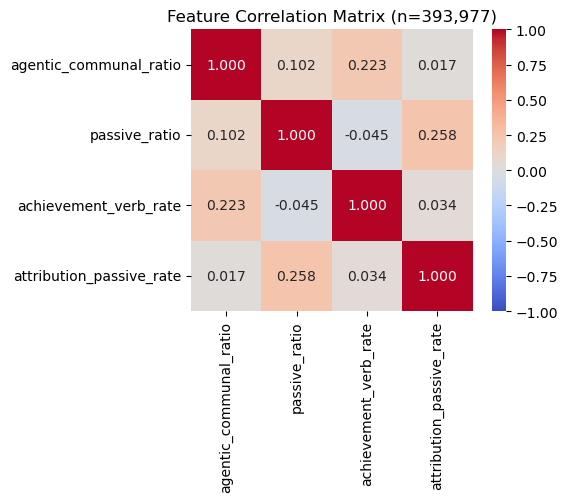

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = ['agentic_communal_ratio', 'passive_ratio',
                 'achievement_verb_rate', 'attribution_passive_rate']

corr_matrix = df_features[feature_cols].corr()
print("=== Feature correlation matrix (Pearson) ===")
print(corr_matrix.round(4))

# -- Multicollinearity gate -----------------------------------------------------
print("\n=== Multicollinearity check (|r| > 0.7) ===")
flagged = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.7:
            flagged.append((feature_cols[i], feature_cols[j], r))
            print(f"  FLAGGED: {feature_cols[i]} vs {feature_cols[j]}: r={r:.4f}")
if not flagged:
    print("  None — no pair exceeds the 0.7 threshold.")

# -- Heatmap --------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Feature Correlation Matrix (n=393,977)')
plt.tight_layout()
plt.savefig('outputs/feature_correlation_matrix.png', dpi=150)
plt.show()

**What is checked here:** the pairwise Pearson correlations among the four
features and whether any pair exceeds the |r| > 0.7 threshold. The matrix and
the result of the check are in the cell output.

Two correlations are mechanically expected and should be positive: F1 with F3,
because the achievement dictionary is a subset of the agency terms, and F2 with
F4, because F4 requires `auxpass` and F2 counts exactly that. Both stay small,
because F3 and F4 are too sparse to drive the variance of F1 and F2.

For context: in the planned Study 1 design each feature is its own dependent
variable (`feature ~ gender + occupation fixed effects + log(word count)`) and
is estimated separately; the four do not enter one model together as
covariates. This check therefore does not establish multicollinearity in a
regression model. It answers whether the four features are so closely related
that they would be measuring the same construct.

## 10. Export to `src/`

The logic validated in this notebook lives in `src/lexicon.py` (parsing the
dictionary and the matchers) and `src/features.py` (the four feature functions
plus `extract_features()` for reuse). This replaces the earlier, unvalidated
versions of both files entirely: the original `AGENTIC_WORDS` /
`COMMUNAL_WORDS` lists (lemma lists after Gaucher et al. 2011) and the
provisional achievement and passive logic are superseded by the `.dic`-based
path validated above.

The smoke test re-imports both modules and recomputes all four features for the
same 20-biography sample. It checks that the values from `src/` match the
notebook's derivation exactly, and that `load_lexicons(version="A")` reads the
same dictionary file as that derivation.

In [11]:
# -- Smoke test: src/ implementation must match inline notebook results -------
import importlib
import src.lexicon, src.features
importlib.reload(src.lexicon)
importlib.reload(src.features)
from src.lexicon import load_lexicons
from src.features import (agentic_communal_ratio as src_acr,
                           passive_ratio as src_pr,
                           achievement_verb_rate as src_avr,
                           external_attribution_rate as src_apr,
                           extract_features)

lex = load_lexicons(version="A")   # the main analysis

# Same path as the derivation above?
from src.lexicon import _DIC_PATHS
assert Path(_DIC_PATHS["A"]) == DIC_PATH, (
    f"path differs: notebook {DIC_PATH}, src/lexicon.py {_DIC_PATHS['A']}")
print(f"Path check passed: load_lexicons(version='A') reads {_DIC_PATHS['A']}")

mismatches = 0
for _, row in sample_df.iterrows():
    doc = nlp(row['text_clean'])

    a_inline, c_inline, acr_inline = f1_agentic_communal_ratio(doc, row['text_clean'])
    a_src, c_src, acr_src           = src_acr(doc, row['text_clean'], lex)
    assert abs(acr_inline - acr_src) < 1e-9, f"F1 ratio mismatch: {acr_inline} vs {acr_src}"
    assert a_inline == a_src, f"F1 agency_count mismatch: {a_inline} vs {a_src}"
    assert c_inline == c_src, f"F1 communion_count mismatch: {c_inline} vs {c_src}"

    _, _, pr_inline, _ = f2_passive_ratio(doc, row['word_count'])
    _, _, pr_src, _     = src_pr(doc, row['word_count'])
    assert abs(pr_inline - pr_src) < 1e-9, f"F2 mismatch: {pr_inline} vs {pr_src}"

    _, avr_inline = f3_achievement_verb_rate(doc, row['word_count'])
    _, avr_src     = src_avr(doc, row['word_count'], lex)
    assert abs(avr_inline - avr_src) < 1e-9, f"F3 mismatch: {avr_inline} vs {avr_src}"

    _, apr_inline, _ = f4_external_attribution_rate(doc, row['word_count'], require_auxpass=True)
    _, apr_src, _     = src_apr(doc, row['word_count'], lex, require_auxpass=True)
    assert abs(apr_inline - apr_src) < 1e-9, f"F4 mismatch: {apr_inline} vs {apr_src}"

print(f"Smoke test passed: all 4 features + agency_count/communion_count match for "
      f"{len(sample_df)} bios (inline notebook logic == src/ logic)")

# -- End-to-end check: extract_features() on the same sample ------------------
df_smoke = extract_features(sample_df, nlp, lex, text_col='text_clean',
                              word_count_col='word_count', use_auxpass_for_f4=True)
print("\nextract_features() output (first 5 rows):")
print(df_smoke[['occupation', 'gender_label', 'agentic_communal_ratio', 'agency_count',
                 'communion_count', 'passive_ratio', 'achievement_verb_rate',
                 'attribution_passive_rate']].head())

Path check passed: load_lexicons(version='A') reads data\lexicons\official\a_AgencyCommunion.dic
Smoke test passed: all 4 features + agency_count/communion_count match for 20 bios (inline notebook logic == src/ logic)

extract_features() output (first 5 rows):
   occupation gender_label  agentic_communal_ratio  agency_count  \
0   professor         Male                    0.00             1   
1       nurse       Female                    0.25             2   
2    attorney       Female                   -0.40             1   
3  journalist         Male                   -0.50             0   
4   professor         Male                   -0.50             0   

   communion_count  passive_ratio  achievement_verb_rate  \
0                1           0.00               2.702703   
1                1           0.00               0.000000   
2                3           0.25               1.515152   
3                1           0.50               0.000000   
4                1           0

**What is checked here:** that `src/lexicon.py` and `src/features.py` produce
exactly the same values as the derivation in this notebook for the same
20-biography sample, across all four features and for `agency_count` /
`communion_count`; that `load_lexicons(version="A")` reads the same dictionary
file; and that `extract_features()` runs end to end. The result of the check is
in the cell output. From here on, the later notebooks can use this logic without
re-deriving the methodology.

## 11. Save `outputs/df_features.parquet`

Saves the feature dataset for `04_study1_analysis.ipynb`. The column list is
unchanged from the state of 2026-10-10; only the values of the
dictionary-dependent columns change, because dictionary A now applies. Cleanup
before saving:

- `wc_diff` is dropped - needed only for the check on the origin of
  `word_count`, not for the analysis.
- Of `attribution_passive_rate_auxpass` and
  `attribution_passive_rate_anyvoice`, whichever column is identical to the
  final `attribution_passive_rate` is dropped; the other is kept as an explicit
  robustness column. `USE_AUXPASS_FINAL` from section 8 decides which, and the
  cell output names it. (An earlier version always dropped the `auxpass`
  variant, which would have silently broken the commitment in section 6 to keep
  the other variant, had the any-voice variant become primary.)
- `agency_count` and `communion_count` pass through unchanged - Notebook 04
  needs them for the agency/communion decomposition, and they cannot be derived
  from the ratio.

In [12]:
# Drop whichever F4 variant duplicates the final attribution_passive_rate;
# keep the other as an explicit robustness column.
redundant_col = ('attribution_passive_rate_auxpass' if USE_AUXPASS_FINAL
                  else 'attribution_passive_rate_anyvoice')
df_final = df_features.drop(columns=[redundant_col, 'wc_diff'])

print(f"Dropped redundant column: {redundant_col}")
print(f"Final shape: {df_final.shape}")
print(f"Columns: {list(df_final.columns)}")

output_path = Path('outputs/df_features.parquet')
df_final.to_parquet(output_path, index=False)

size_mb = output_path.stat().st_size / (1024 * 1024)
print(f"\nSaved to {output_path} ({size_mb:.1f} MB)")
print(f"\nNull check:")
robustness_col = ('attribution_passive_rate_anyvoice' if USE_AUXPASS_FINAL
                    else 'attribution_passive_rate_auxpass')
print(df_final[['agentic_communal_ratio', 'passive_ratio', 'achievement_verb_rate',
                  'attribution_passive_rate', robustness_col]].isnull().sum())

Dropped redundant column: attribution_passive_rate_auxpass
Final shape: (393977, 14)
Columns: ['hard_text', 'text_clean', 'profession', 'occupation', 'gender', 'gender_label', 'word_count', 'agentic_communal_ratio', 'agency_count', 'communion_count', 'passive_ratio', 'achievement_verb_rate', 'attribution_passive_rate_anyvoice', 'attribution_passive_rate']

Saved to outputs\df_features.parquet (183.2 MB)

Null check:
agentic_communal_ratio               0
passive_ratio                        0
achievement_verb_rate                0
attribution_passive_rate             0
attribution_passive_rate_anyvoice    0
dtype: int64


**What is checked here:** the shape of the saved dataset (rows and columns),
that none of the feature columns contains missing values, and which F4 variant
is retained as the robustness column. The values are in the cell output.

Notebook 03 is complete: four features computed, checked and exported to
`src/lexicon.py` and `src/features.py`, together with the raw hit counts for F1
- ready for `04_study1_analysis.ipynb`.